# Detecting Fraudulent Job Postings

- **Course:** Programming for AI and Data Science (4IZ582)
- **Semester:** Winter 2026/27
- **Authors:** Olesia Cheremnykh, Julia Urs, Anastasija Kipcevič

**Research question.** Do text embeddings help detect fraudulent job postings more effectively than TF-IDF?

We compare TF-IDF and embeddings with two classifiers: logistic regression and random forest. This 2-by-2 design lets us compare representations within each classifier and classifiers within each representation.

We use the [Real or Fake? Fake Jobposting Prediction](https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction) dataset. Each row represents one job posting. The target, `fraudulent`, is `0` for legitimate postings and `1` for fraudulent postings. We use `job_id` to match records.

### Environment setup

Install the packages in the Python environment used by Jupyter:

```bash
python -m pip install "pandas>=2.2,<4" "numpy>=2,<3" "matplotlib>=3.9,<4" "scikit-learn>=1.6,<2" lxml "joblib>=1.4,<2" "ipykernel>=6,<8" "nbconvert>=7,<8"
```

Only generating new embeddings requires `litellm` and `python-dotenv`.

Keep `baseline_training.joblib`, `random_forest_training.joblib` and `tfidf_test_results.joblib` in `data/`. They contain our nested-CV models and test results, so repeat runs load them without retraining or predicting on test again. Without the training files, the TF-IDF cells repeat nested CV. Embeddings need the separate school cache described below.

## 1. Exploratory Data Analysis

We inspect the dataset size, column types, missing values, and class balance. We then compare the share of fraudulent postings across groups defined by company logo, remote-work flag, and employment type.

We also inspected other variables, but decided not to include every graph in our Jupyter Notebook, otherwise it would be too long.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path('data/fake_job_postings.csv')
jobs = pd.read_csv(DATA_PATH)

n_rows, n_columns = jobs.shape
print(f'Dataset size: {n_rows:,} rows × {n_columns} columns')
jobs[['job_id', 'title', 'location', 'employment_type', 'fraudulent']].head(5)

Dataset size: 17,880 rows × 18 columns


,job_id,title,location,employment_type,fraudulent
0,1,Marketing Intern,"US, NY, New York",Other,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Full-time,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Full-time,0
4,5,Bill Review Manager,"US, FL, Fort Worth",Full-time,0


### Data types and missing values

The table shows the data type, the number and share of missing values, and the missing rate within each class. We count empty and whitespace-only strings as missing. The chart shows fields with at least one missing value.

In [2]:
CLASS_LABELS = {0: "Legitimate", 1: "Fraudulent"}
CLASS_COLORS = {0: "#326C96", 1: "#BB5043"}
TEXT_COLOR = "#253747"


def style_axes(ax, title, grid_axis="y"):
    ax.set_title(title, loc="left", pad=12, fontweight="bold", color=TEXT_COLOR)
    ax.set_axisbelow(True)
    ax.grid(axis=grid_axis, color="#E1E8EF", linewidth=0.8)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0, pad=6, colors=TEXT_COLOR)
    ax.xaxis.label.set_color(TEXT_COLOR)
    ax.yaxis.label.set_color(TEXT_COLOR)

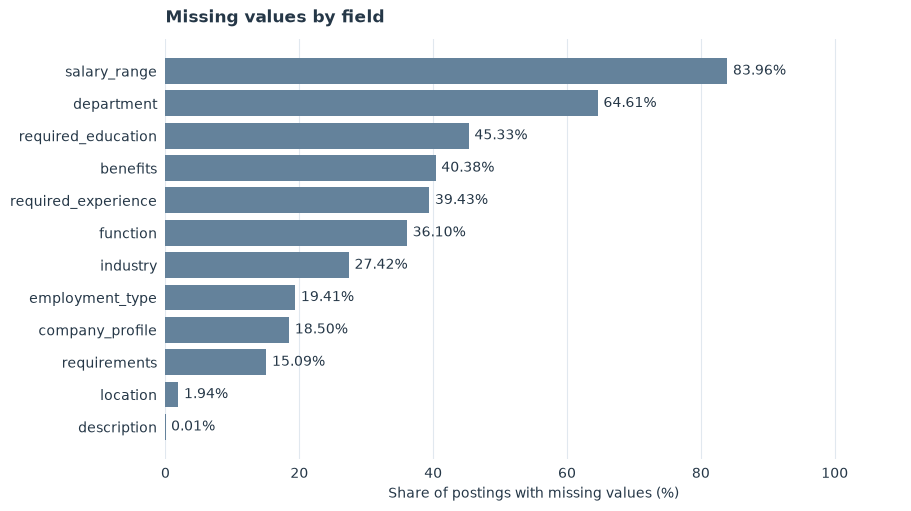

,Data type,Missing count,Missing (%),Missing in legitimate postings (%),Missing in fraudulent postings (%)
salary_range,str,15012,83.96,84.45,74.25
department,str,11553,64.61,64.78,61.32
required_education,str,8105,45.33,44.99,52.08
benefits,str,7220,40.38,40.30,42.03
required_experience,str,7050,39.43,38.88,50.23
function,str,6455,36.10,35.96,38.91
industry,str,4903,27.42,27.20,31.76
employment_type,str,3471,19.41,18.98,27.83
company_profile,str,3308,18.50,15.99,67.78
requirements,str,2698,15.09,14.95,17.78


In [3]:
missing = jobs.replace(r"^\s*$", pd.NA, regex=True).isna()
by_class = missing.groupby(jobs["fraudulent"], observed=True).mean().T
by_class = by_class.reindex(columns=[0, 1]) * 100

data_profile = pd.DataFrame({
    "Data type": jobs.dtypes.astype(str),
    "Missing count": missing.sum(),
    "Missing (%)": missing.mean() * 100,
    "Missing in legitimate postings (%)": by_class[0],
    "Missing in fraudulent postings (%)": by_class[1],
}).round(2).sort_values("Missing count", ascending=False)

with_missing = data_profile.loc[data_profile["Missing count"] > 0]

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
bars = ax.barh(with_missing.index, with_missing["Missing (%)"], color="#64829B")
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f%%", padding=4, color=TEXT_COLOR)
ax.set(xlabel="Share of postings with missing values (%)", xlim=(0, 110), xticks=range(0, 101, 20))
style_axes(ax, "Missing values by field", grid_axis="x")
plt.show()

data_profile

The fields most often missing are `salary_range` (84.0%) and `department` (64.6%). Around 40% of postings also lack `benefits`. This is the case for both legitimate and fraudulent postings. 

Interestingly, almost 70% of fraudulent job postings do not contain the variable `company_profile`, which is 4 times higher than in legitimate postings.

We replace missing values in the five text fields with empty strings so that we can keep any posting with text in at least one of those fields.

### Class balance

The bar chart shows the number and percentage of legitimate (`0`) and fraudulent (`1`) postings in the original dataset, before duplicate removal.

            Count  Percent
Class                     
Legitimate  17014    95.16
Fraudulent    866     4.84


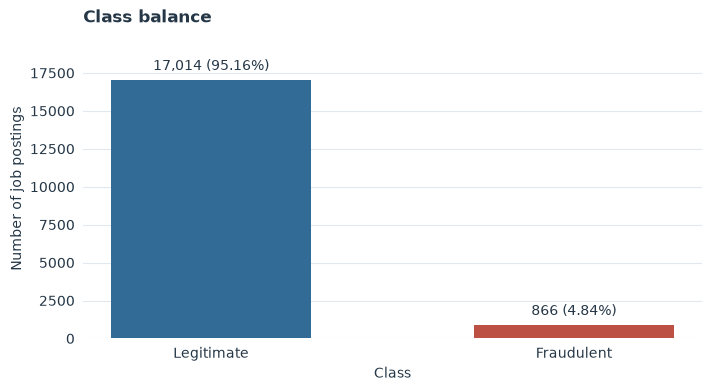

Always predicting legitimate gives 95.16% accuracy.


In [4]:
def analyze_class_balance(df):
    counts = df["fraudulent"].value_counts().reindex([0, 1], fill_value=0)
    percentages = counts / len(df) * 100
    summary = pd.DataFrame({"Count": counts, "Percent": percentages.round(2)})
    print(summary.rename(index=CLASS_LABELS).rename_axis("Class"))

    fig, ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
    bars = ax.bar(
        [CLASS_LABELS[label] for label in counts.index],
        counts,
        color=[CLASS_COLORS[label] for label in counts.index],
        width=0.55,
    )
    labels = [f"{count:,} ({pct:.2f}%)" for count, pct in zip(counts, percentages)]
    ax.bar_label(bars, labels=labels, padding=5, color=TEXT_COLOR)
    ax.set(xlabel="Class", ylabel="Number of job postings", ylim=(0, counts.max() * 1.16))
    style_axes(ax, "Class balance")
    plt.show()

    print(f"Always predicting legitimate gives {percentages[0]:.2f}% accuracy.")
    return summary

class_balance = analyze_class_balance(jobs)

Only **866 of 17,880 postings (4.84%)** are fraudulent. Predicting every posting as legitimate gives **95.16% accuracy**, but finds no fraud. Accuracy alone is therefore misleading.

We select models by fraud-class F1, which balances precision and recall. We also report Average Precision (AP), which summarizes the precision–recall trade-off across thresholds. The Dummy baseline later shows this majority-class behaviour on the modelling splits.

### Job posting characteristics

Each bar shows the class breakdown within a group. The label above the bar gives the share of fraudulent postings. The label below gives the group size.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


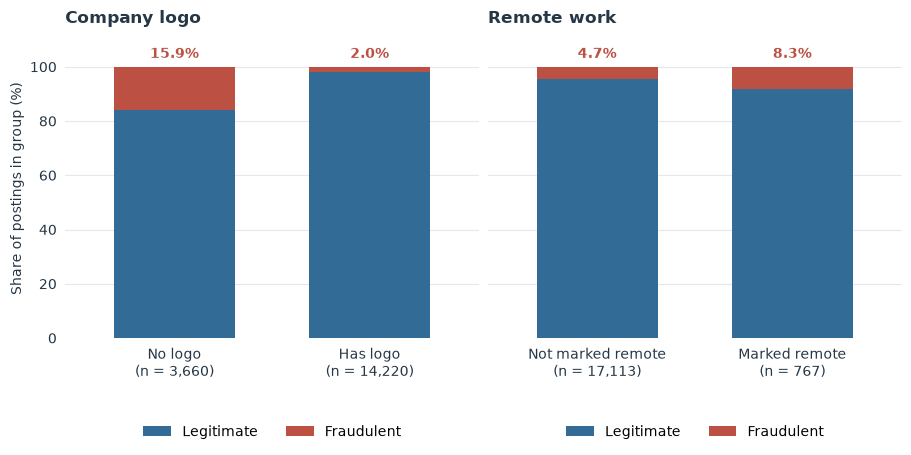

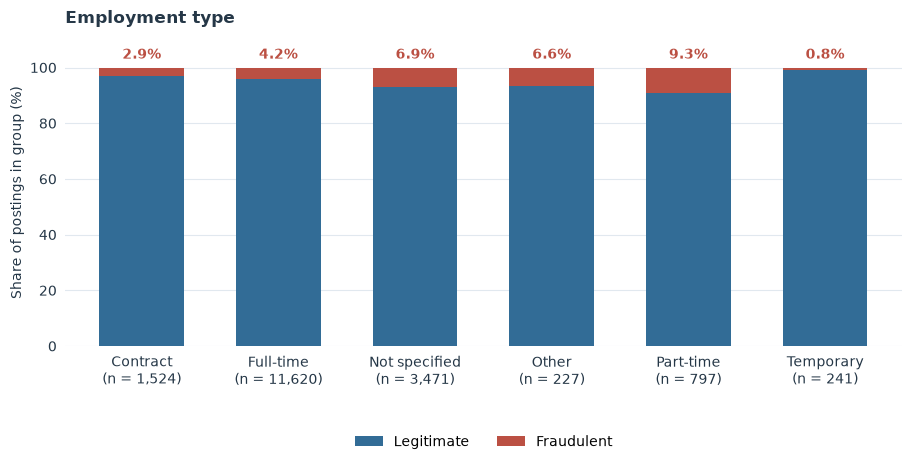

In [5]:
def fraud_bars(jobs, feature, ax, title, *, group_labels=None):
    groups = jobs[feature]
    if groups.isna().any():
        groups = groups.astype("string").fillna("Missing")
    counts = pd.crosstab(groups, jobs["fraudulent"])
    counts = counts.reindex(columns=[0, 1], fill_value=0)
    counts.columns = ["Real", "Fake"]
    totals = counts.sum(axis=1)
    shares = counts.div(totals, axis=0) * 100

    group_labels = group_labels or {}
    shares.index = [f"{group_labels.get(group, group)}\n(n = {n:,})" for group, n in totals.items()]
    shares.rename(columns={"Real": CLASS_LABELS[0], "Fake": CLASS_LABELS[1]}).plot.bar(
        stacked=True, ax=ax, color=list(CLASS_COLORS.values()), width=0.62, rot=0
    )
    ax.bar_label(
        ax.containers[1],
        labels=[f"{pct:.1f}%" for pct in shares["Fake"]],
        padding=4,
        color=CLASS_COLORS[1],
        fontweight="semibold",
    )
    ax.set(ylabel="Share of postings in group (%)", xlabel="", ylim=(0, 110), yticks=range(0, 101, 20))
    style_axes(ax, title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
    return counts


def plot_job_features(jobs):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.4), sharey=True, layout="constrained")
    fraud_bars(jobs, "has_company_logo", axes[0], "Company logo",
               group_labels={0: "No logo", 1: "Has logo"})
    fraud_bars(jobs, "telecommuting", axes[1], "Remote work",
               group_labels={0: "Not marked remote", 1: "Marked remote"})
    axes[1].set_ylabel("")

    employment_labels = {"Missing": "Not specified"}
    fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
    fraud_bars(jobs, "employment_type", ax, "Employment type", group_labels=employment_labels)


plot_job_features(jobs)
plt.show()

The fraud rate is **15.9%** for postings without a company logo and **2.0%** for postings with one. It is **8.3%** for postings marked as remote and **4.7%** for postings without the flag. Legitimate postings make up the majority in all these groups.

The fraud rate is higher for part-time postings than for full-time postings (**9.3%** versus **4.2%**). The groups also differ in size. These comparisons describe the source dataset. Our main experiment compares two representations of the same posting text.

## 2. Data Preparation

### Combine fields and remove HTML

We use `title`, `company_profile`, `description`, `requirements`, and `benefits`. Missing values become empty strings so that a missing field does not remove a useful posting. We join the five fields with spaces and remove HTML from the combined text. The next step replaces links and contact details.

We check that originally missing cells are empty, not literal `"nan"` or `"None"`, and that `text` has no missing values. Fully empty postings are excluded. `word_count` and `filled_fields` describe text length and completeness for EDA; only `text` enters the classifiers.

In [6]:
import re
from html import unescape

from lxml import html

TEXT_COLUMNS = ['title', 'company_profile', 'description', 'requirements', 'benefits']
METADATA_COLUMNS = [
    'location', 'department', 'salary_range', 'employment_type',
    'required_experience', 'required_education', 'industry', 'function',
]

def clean_html_text(value):
    if pd.isna(value):
        return ''

    text = unescape(str(value))
    if re.search(r'<(?:/?[a-zA-Z][^>]*|!--.*?)>', text, flags=re.S):
        document = html.fragment_fromstring(text, create_parent='div')
        for element in document.xpath('.//script | .//style'):
            element.drop_tree()
        text = ' '.join(document.itertext())

    return ' '.join(text.split())

In [7]:
cleaned_jobs = jobs.copy()
text_fields = jobs[TEXT_COLUMNS].fillna("")
joined_text = text_fields.agg(" ".join, axis=1)
html_cleaned_text = joined_text.map(clean_html_text)

# Check the originally missing cells, not legitimate words inside real text.
for column in TEXT_COLUMNS:
    assert text_fields.loc[jobs[column].isna(), column].eq("").all()
assert text_fields.notna().all().all()

metadata_fields = jobs[METADATA_COLUMNS].fillna("")
cleaned_jobs["filled_fields"] = (
    text_fields.apply(lambda field: field.str.strip().ne("")).sum(axis=1)
    + metadata_fields.apply(lambda field: field.str.strip().ne("")).sum(axis=1)
)

The scan below reports how often the joined text contains literal HTML tags or encoded entities before cleaning.

In [8]:
has_tags = joined_text.str.contains(r"<[a-zA-Z/][^>]*>", regex=True)
has_entities = joined_text.str.contains(r"&[a-zA-Z]+;|&#\d+;", regex=True)

print(f"Rows with HTML tags: {has_tags.mean():.2%}")
print(f"Rows with HTML entities: {has_entities.mean():.2%}")

Rows with HTML tags: 0.00%
Rows with HTML entities: 42.75%


### Replace links and contact details

We replace links, email addresses, and phone numbers with short labels. TF-IDF and embeddings use the same final column, `text`.

The example below shows each step on a short sample posting.

In [9]:
domain = r"(?:[a-z0-9-]+\.)+[a-z]{2,63}(?![\w-])"
url_character = r"""[^\s<>"'#]"""
url_prefix = r"(?:https?://|www\.)"
url_path_start = r"(?:[/:?]|#(?!(?:URL|EMAIL|PHONE)_))"
url_path = rf"(?:{url_path_start}{url_character}*)?"
masked_url = r"#URL_[0-9a-f]{64}#"
masked_email = r"#EMAIL_[0-9a-f]{64}#"
masked_phone = r"#PHONE_[0-9a-f]{64}#"
masked_url_with_prefix = (
    rf"(?:{url_prefix}{url_character}*\s*)?{masked_url}"
)
regular_url = (
    rf"\b(?:https?://(?:www\.)?|www\.){domain}{url_path}"
)
email_username = r"(?<![\w.%+-])[\w.%+-]+"
regular_email = rf"{email_username}@{domain}"
phone_start = r"(?<![\w./-])"
phone_end = r"(?![\w/-]|\.\d)"
international_phone = r"\+\d{8,15}"
grouped_international_phone = (
    r"\+\d{1,3}(?:[\s\u2013-]+(?:\(\d{1,4}\)|\d{1,5})){2,5}"
)
us_phone = (
    r"(?:1[ .-])?"
    r"(?:\(\d{3}\)[ .-]?|\d{3}[ .-])"
    r"\d{3}[ .-]\d{4}"
)
phone_formats = "|".join(
    [international_phone, grouped_international_phone, us_phone]
)
regular_phone = rf"{phone_start}(?:{phone_formats}){phone_end}"

patterns = {
    "URL": rf"{masked_url_with_prefix}|{regular_url}",
    "EMAIL": rf"{masked_email}|{regular_email}",
    "PHONE": rf"{masked_phone}|{regular_phone}",
}

named_patterns = [
    rf"(?P<{kind}>{pattern})"
    for kind, pattern in patterns.items()
]
contacts = re.compile( "|".join( named_patterns ), re.I )

call_label = r"call(?: (?:us|me))?(?: (?:at|on))?"
phone_label = rf"(?:phone|tel(?:ephone)?|fax|mobile|{call_label})"
labelled_number = r"[+(]?\d(?:[\d() \u2013-]*\d)"

short_phone = re.compile(
    rf"\b({phone_label}\s*:?\s+)({labelled_number}){phone_end}",
    re.I,
)


def replace_contact(match):
    value, kind = match[0], match.lastgroup
    if kind == "PHONE" and not value.startswith("#"):
        if not 8 <= sum(char.isdigit() for char in value) <= 15:
            return value

    punctuation = value[len(value.rstrip(".,;:!?)]}")):] if kind == "URL" else ""
    left = match.string[max(0, match.start() - 1):match.start()]
    right = match.string[match.end():match.end() + 1]
    before = " " if left.isalnum() or left == "#" else ""
    after = " " if right.isalnum() and not punctuation else ""
    return f"{before}[{kind}]{punctuation}{after}"


def replace_short_phone(match):
    digits = sum(char.isdigit() for char in match[2])
    return f"{match[1]}[PHONE]" if 7 <= digits <= 15 else match[0]


def normalize_contacts(text):
    return short_phone.sub(replace_short_phone, contacts.sub(replace_contact, text))


cleaned_jobs["text"] = html_cleaned_text.map(normalize_contacts)
cleaned_jobs["word_count"] = cleaned_jobs["text"].str.split().str.len()
text_jobs = cleaned_jobs.loc[cleaned_jobs["text"].ne("")].copy()

example_joined = " ".join(["<b>Data Analyst</b>", "<p>Send your CV to jobs@example.com.</p>", "SQL required."])
example_without_html = clean_html_text(example_joined)
example_text = normalize_contacts(example_without_html)
cleanup_example = pd.Series({
    "1. Joined fields": example_joined,
    "2. HTML removed": example_without_html,
    "3. Contact replaced": example_text,
}, name="Text").rename_axis("Step").to_frame()
cleanup_example

,Text
Step,
1. Joined fields,<b>Data Analyst</b> <p>Send your CV to jobs@ex...
2. HTML removed,Data Analyst Send your CV to jobs@example.com....
3. Contact replaced,Data Analyst Send your CV to [EMAIL]. SQL requ...


### Word count after cleaning

We compare word counts between classes and look at the class breakdown within each word count range. Both plots use postings with non-empty text before duplicate removal.

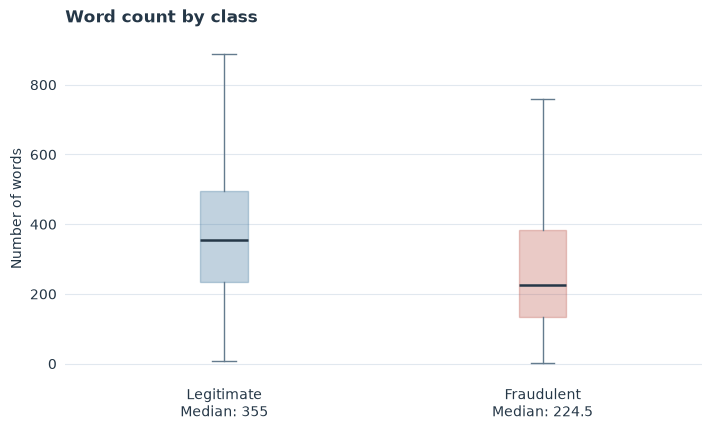

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
text_jobs.boxplot(
    column="word_count", by="fraudulent", ax=ax, grid=False, showfliers=False,
    patch_artist=True, medianprops={"color": TEXT_COLOR, "linewidth": 1.8},
    whiskerprops={"color": "#647B8E"}, capprops={"color": "#647B8E"},
)

medians = text_jobs.groupby("fraudulent")["word_count"].median().sort_index()
labels = [f"{CLASS_LABELS[label]}\nMedian: {median:g}" for label, median in medians.items()]
ax.set_xticks(range(1, len(labels) + 1), labels=labels)
for label, box in zip(medians.index, ax.patches):
    box.set_facecolor(CLASS_COLORS[label])
    box.set_edgecolor(CLASS_COLORS[label])
    box.set_alpha(0.3)

fig.suptitle("")
ax.set_title("")
ax.set(xlabel="", ylabel="Number of words")
style_axes(ax, "Word count by class")
plt.show()

Fraudulent postings have a lower median word count. The distributions overlap substantially, so word count alone gives limited information about whether a posting is fraudulent. The plot hides points beyond the whiskers so the main distributions are easier to read.

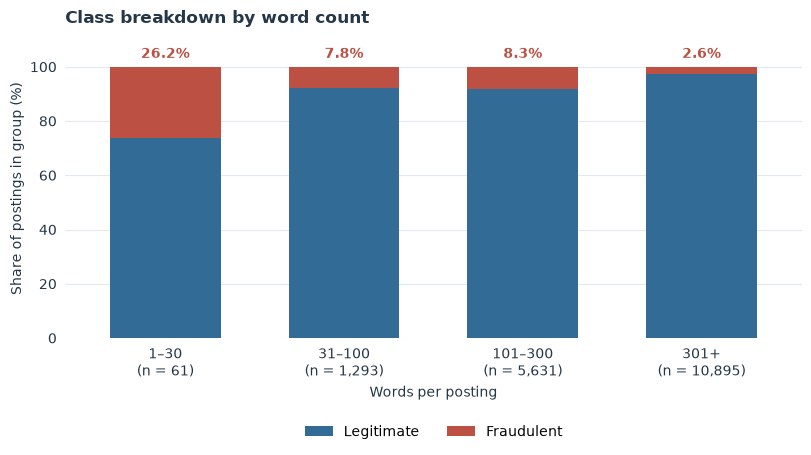

,Legitimate,Fraudulent
Word count range,,
1–30,45,16
31–100,1192,101
101–300,5164,467
301+,10613,282


In [11]:
def plot_text_length(jobs):
    groups = pd.cut(
        jobs["word_count"],
        bins=[0, 30, 100, 300, float("inf")],
        labels=["1–30", "31–100", "101–300", "301+"],
    )

    fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
    counts = fraud_bars(
        jobs.assign(text_length_group=groups),
        "text_length_group",
        ax,
        "Class breakdown by word count",
    )
    ax.set_xlabel("Words per posting")
    return counts


length_counts = plot_text_length(text_jobs)
plt.show()
length_counts.rename(columns={"Real": "Legitimate", "Fake": "Fraudulent"}).rename_axis("Word count range")

Of the **61** postings with 1 to 30 words, **16** are fraudulent (**26.2%**). The fraud rate is **2.6%** among postings with at least 301 words. The shortest group is small, and we keep these postings because they include fraudulent examples.

### Duplicate postings and conflicting labels

We compare the final cleaned text and all other feature columns. We exclude the posting ID and fraud label from the comparison.

If the features and labels match, we keep the first posting. If the features match and the labels disagree, we remove the entire group. Postings with different metadata, such as location, stay in the dataset.

In [12]:
duplicate_columns = jobs.columns.drop(["job_id", "fraudulent", *TEXT_COLUMNS]).tolist() + ["text"]
label_counts = text_jobs.groupby(duplicate_columns, dropna=False)["fraudulent"].transform("nunique")
conflicting_labels = label_counts.gt(1)
consistent_jobs = text_jobs.loc[~conflicting_labels]
deduplicated_jobs = consistent_jobs.drop_duplicates(subset=duplicate_columns).copy()

preparation_summary = pd.Series({
    "Original postings": len(jobs),
    "Empty texts removed": len(jobs) - len(text_jobs),
    "Rows with conflicting labels removed": int(conflicting_labels.sum()),
    "Full duplicate rows removed": len(consistent_jobs) - len(deduplicated_jobs),
    "Postings ready to split": len(deduplicated_jobs),
    "Extra copies of identical text (before)": int(text_jobs["text"].duplicated().sum()),
    "Extra copies of identical text (after)": int(deduplicated_jobs["text"].duplicated().sum()),
}, name="Postings").to_frame()
preparation_summary

,Postings
Original postings,17880
Empty texts removed,0
Rows with conflicting labels removed,0
Full duplicate rows removed,328
Postings ready to split,17552
Extra copies of identical text (before),2007
Extra copies of identical text (after),1679


### Train/test split and cross-validation

We group postings by cleaned description, using the full text if the description is empty. All models use the same 80/20 split and the same five cross-validation folds. The test set is reserved for final evaluation.

In [13]:
from sklearn.model_selection import StratifiedGroupKFold

RANDOM_STATE = 42
N_SPLITS = 5


grouped_jobs = deduplicated_jobs.reset_index(drop=True)
description_key = grouped_jobs["description"].map(clean_html_text).map(normalize_contacts)
description_key = description_key.str.casefold()
text_key = grouped_jobs["text"].str.casefold()
group_key = description_key.mask(description_key.eq(""), text_key)
grouped_jobs["group_id"] = pd.factorize(group_key)[0]

splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
train_indices, test_indices = next(splitter.split(
    grouped_jobs, grouped_jobs["fraudulent"], groups=grouped_jobs["group_id"]
))
train_df = grouped_jobs.iloc[train_indices].reset_index(drop=True)
test_df = grouped_jobs.iloc[test_indices].reset_index(drop=True)

cv_splits = list(splitter.split(train_df, train_df["fraudulent"], groups=train_df["group_id"]))

split_summary = pd.DataFrame([
    {
        "Split": name,
        "Postings": len(frame),
        "Share of data (%)": 100 * len(frame) / len(grouped_jobs),
        "Fraud rate (%)": 100 * frame["fraudulent"].mean(),
    }
    for name, frame in [("Train", train_df), ("Test", test_df)]
]).set_index("Split").round(2)
split_summary

,Postings,Share of data (%),Fraud rate (%)
Split,,,
Train,14041,80.0,4.88
Test,3511,20.0,4.87


### Check for overlap

The table checks that train/test and each CV fold share no posting IDs, groups, or identical model inputs.

In [14]:
def check_split(name, fit_rows, evaluation_rows):
    return {
        "Comparison": name,
        "Evaluation postings": len(evaluation_rows),
        "Fraud rate (%)": 100 * evaluation_rows["fraudulent"].mean(),
        "Shared posting IDs": len(set(fit_rows["job_id"]) & set(evaluation_rows["job_id"])),
        "Shared groups": len(set(fit_rows["group_id"]) & set(evaluation_rows["group_id"])),
        "Shared texts": len(set(fit_rows["text"]) & set(evaluation_rows["text"])),
    }


split_checks = [check_split("Train vs. test", train_df, test_df)]
for fold, (fit_indices, validation_indices) in enumerate(cv_splits, start=1):
    split_checks.append(check_split(
        f"CV fold {fold}", train_df.iloc[fit_indices], train_df.iloc[validation_indices]
    ))

split_checks = pd.DataFrame(split_checks).set_index("Comparison").round(2)
overlap_columns = ["Shared posting IDs", "Shared groups", "Shared texts"]
assert split_checks[overlap_columns].eq(0).all().all(), "Posting overlap found across splits"
split_checks

,Evaluation postings,Fraud rate (%),Shared posting IDs,Shared groups,Shared texts
Comparison,,,,,
Train vs. test,3511,4.87,0,0,0
CV fold 1,2809,4.88,0,0,0
CV fold 2,2808,4.88,0,0,0
CV fold 3,2808,4.88,0,0,0
CV fold 4,2808,4.88,0,0,0
CV fold 5,2808,4.88,0,0,0


## 3. Text classification

| Input | Logistic Regression | Random Forest |
|---|---|---|
| TF-IDF | Word features + LR | Word features + RF |
| School embeddings | Dense vectors + LR | Dense vectors + RF |

### Shared nested cross-validation

All four models use the same test set and five outer folds within train. Three inner folds select hyperparameters by fraud-class F1. We create these splits once for both representations; grouping keeps related postings together, and fixed random seeds make the splits reproducible.

Each outer validation fold is excluded from fitting and parameter selection. Its F1 and AP evaluate the tuning procedure. A final three-fold search selects parameters and refits each pipeline on all train. Compact grids keep computation manageable. All learned transformations stay inside pipelines; the search grids can differ between representations.

In [15]:
from time import perf_counter

import numpy as np
from sklearn.metrics import average_precision_score, f1_score, make_scorer
from sklearn.model_selection import GridSearchCV

INNER_CV_FOLDS = 3
INNER_CV_SEED = 1
F1_SCORER = make_scorer(f1_score, zero_division=0)


def fit_on_train(estimator, X, y, param_grid, inner_splits):
    # All representations receive exactly the same inner row indices.
    search = GridSearchCV(
        estimator, param_grid, scoring=F1_SCORER,
        cv=inner_splits, refit=True, n_jobs=1, error_score="raise",
    )
    search.fit(X, y)
    return search.best_estimator_, search.best_params_


def train_with_cv(estimator, X, y, groups, outer_splits, param_grid):
    started = perf_counter()
    fold_f1 = []
    fold_ap = []
    fold_parameters = []
    oof_scores = np.full(len(y), np.nan)

    # The shared plans were made for this exact row order and these outer folds.
    assert np.array_equal(y, y_train)
    assert np.array_equal(groups, train_groups)
    assert len(outer_splits) == len(cv_splits)
    for old, current in zip(outer_splits, cv_splits):
        assert all(np.array_equal(a, b) for a, b in zip(old, current))

    for fold, (fit, validation) in enumerate(outer_splits):
        print(f"Outer fold {fold + 1}/{len(outer_splits)}", flush=True)
        validation_model, parameters = fit_on_train(
            estimator, X[fit], y[fit], param_grid, inner_cv_splits[fold],
        )
        positive_column = list(validation_model.classes_).index(1)
        scores = validation_model.predict_proba(X[validation])[:, positive_column]
        oof_scores[validation] = scores
        fold_f1.append(F1_SCORER(validation_model, X[validation], y[validation]))
        fold_ap.append(average_precision_score(y[validation], scores))
        fold_parameters.append(parameters)

    assert np.isfinite(oof_scores).all(), "Missing out-of-fold scores"
    print("Final inner search and refit on all train", flush=True)
    final_model, best_params = fit_on_train(
        estimator, X, y, param_grid, final_inner_splits,
    )
    return {
        "model": final_model,
        "best_params": best_params,
        "fold_f1": fold_f1,
        "fold_ap": fold_ap,
        "fold_parameters": fold_parameters,
        "oof_scores": oof_scores,
        "seconds": perf_counter() - started,
        "train_ids": train_df["job_id"].tolist(),
        "outer_splits": outer_splits,
        "inner_splits": inner_cv_splits,
        "final_inner_splits": final_inner_splits,
    }

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

EMB_LR_PARAM_GRID = {"classifier__C": [0.0001, 0.001, 0.01, 0.1, 1.0]}
RF_PARAM_GRID = {"classifier__max_depth": [10, 30]}

y_train = train_df["fraudulent"].to_numpy()
train_groups = train_df["group_id"].to_numpy()
model_results = {}


def logistic_regression():
    return LogisticRegression(
        solver="liblinear", max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    )


def random_forest():
    return RandomForestClassifier(
        n_estimators=100, min_samples_leaf=3, class_weight="balanced_subsample",
        n_jobs=2, random_state=RANDOM_STATE,
    )

# Build the inner splits once, independently of the text representation.
inner_splitter = StratifiedGroupKFold(
    n_splits=INNER_CV_FOLDS, shuffle=True, random_state=INNER_CV_SEED,
)
inner_cv_splits = []
for fit, validation in cv_splits:
    splits = list(inner_splitter.split(
        np.zeros(len(fit)), y_train[fit], train_groups[fit],
    ))
    for inner_fit, inner_validation in splits:
        assert set(train_groups[fit[inner_fit]]).isdisjoint(
            set(train_groups[fit[inner_validation]])
        )
    inner_cv_splits.append(splits)

final_inner_splits = list(inner_splitter.split(
    np.zeros(len(y_train)), y_train, train_groups,
))
print("Shared CV plan: 5 outer folds, 3 inner folds, and 3 final tuning folds.")

Shared CV plan: 5 outer folds, 3 inner folds, and 3 final tuning folds.


### 3.1 Dummy baseline

DummyClassifier always predicts the majority class: legitimate. It ignores text and has no settings to tune. We evaluate it on the same outer folds and test set as a reference: high accuracy can coexist with zero fraud recall and F1.

In [17]:
import joblib
from tempfile import TemporaryDirectory
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

X_train_text = train_df["text"].to_numpy()
baseline_path = Path("data/baseline_training.joblib")
if baseline_path.exists():
    baseline = joblib.load(baseline_path)
    dummy_result = baseline["dummy_result"]
else:
    dummy_result = train_with_cv(
        DummyClassifier(strategy="most_frequent"), X_train_text.reshape(-1, 1),
        y_train, train_groups, cv_splits, {},
    )

model_results["Dummy"] = dummy_result
print("Dummy outer F1:", np.mean(dummy_result["fold_f1"]))

Dummy outer F1: 0.0


### 3.2 TF-IDF + Logistic Regression

TF-IDF converts posting text into weighted word features. Logistic Regression is our linear classifier. Vocabulary and weights are learned inside each fitting fold, preventing leakage from validation text.

We try single words or words with adjacent word pairs, `min_df` of 2 or 5, `C` of 1 or 10, and ordinary or balanced class weights: 16 combinations. `min_df` removes very rare terms; smaller `C` means stronger regularization. Balanced weights give more importance to the rare fraud class. The 20,000-feature limit bounds computation.

In [18]:
TFIDF_LR_GRID = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 5],
    "classifier__C": [1, 10],
    "classifier__class_weight": [None, "balanced"],
}
baseline_path = Path("data/baseline_training.joblib")
if baseline_path.exists():
    baseline = joblib.load(baseline_path)
    tfidf_lr_result = baseline["logistic_result"]
    print("Loaded nested-CV TF-IDF + Logistic Regression.")
else:
    with TemporaryDirectory(prefix="tfidf-nested-lr-") as vectorizer_cache:
        tfidf_lr = Pipeline([
            ("tfidf", TfidfVectorizer(max_features=20000)),
            ("classifier", LogisticRegression(
                solver="liblinear", max_iter=1000, random_state=RANDOM_STATE,
            )),
        ], memory=vectorizer_cache)
        tfidf_lr_result = train_with_cv(
            tfidf_lr, X_train_text, y_train, train_groups, cv_splits, TFIDF_LR_GRID,
        )
        tfidf_lr_result["model"].memory = None

model_results["TF-IDF + Logistic Regression"] = tfidf_lr_result
print("Selected LR parameters:", tfidf_lr_result["best_params"])

Loaded nested-CV TF-IDF + Logistic Regression.
Selected LR parameters: {'classifier__C': 10, 'classifier__class_weight': 'balanced', 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 2)}


### 3.3 TF-IDF + Random Forest

Random Forest combines decision trees, giving a second algorithm family to compare with the linear classifier. We fix 100 trees to keep training manageable and use balanced subsample weights for class imbalance.

The grid tries words or words with adjacent pairs, depth 30 or no limit, and minimum leaf size 1 or 3: 8 combinations. Depth and leaf size control tree complexity. TF-IDF uses up to 20,000 features and `min_df=2`. The outer and inner folds are shared with the other models.

In [19]:
TFIDF_RF_GRID = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "classifier__max_depth": [30, None],
    "classifier__min_samples_leaf": [1, 3],
}
forest_path = Path("data/random_forest_training.joblib")
if forest_path.exists():
    tfidf_rf_result = joblib.load(forest_path)
    print("Loaded nested-CV TF-IDF + Random Forest.")
else:
    with TemporaryDirectory(prefix="tfidf-nested-rf-") as vectorizer_cache:
        tfidf_rf = Pipeline([
            ("tfidf", TfidfVectorizer(max_features=20000, min_df=2)),
            ("classifier", RandomForestClassifier(
                n_estimators=100, class_weight="balanced_subsample",
                n_jobs=2, random_state=RANDOM_STATE,
            )),
        ], memory=vectorizer_cache)
        tfidf_rf_result = train_with_cv(
            tfidf_rf, X_train_text, y_train, train_groups, cv_splits, TFIDF_RF_GRID,
        )
        tfidf_rf_result["model"].memory = None
    joblib.dump(tfidf_rf_result, forest_path)

model_results["TF-IDF + Random Forest"] = tfidf_rf_result
print("Selected RF parameters:", tfidf_rf_result["best_params"])

Loaded nested-CV TF-IDF + Random Forest.
Selected RF parameters: {'classifier__max_depth': 30, 'classifier__min_samples_leaf': 3, 'tfidf__ngram_range': (1, 2)}


### Choosing TF-IDF decision thresholds

Out-of-fold (OOF) probabilities come from outer-fold models that did not use those validation rows for fitting or parameter selection. We select each threshold by maximum fraud-class F1 on these probabilities; ties favour the higher threshold. A higher threshold is stricter, so the model labels fewer postings as fraudulent and usually creates fewer false alarms when F1 is the same.

The chosen thresholds are **0.5713 for Logistic Regression** and **0.3951 for Random Forest**. A score at or above the threshold means fraud. We choose the threshold on the training data to balance detected fraud and false alarms. The selected threshold is then fixed before the final test evaluation.

In [20]:
from sklearn.metrics import precision_recall_curve


def select_oof_threshold(actual, scores):
    precision, recall, thresholds = precision_recall_curve(actual, scores)
    table = pd.DataFrame({
        "Threshold": thresholds,
        "OOF precision": precision[:-1],
        "OOF recall": recall[:-1],
    })
    precision = table["OOF precision"]
    recall = table["OOF recall"]
    table["OOF F1"] = (2 * precision * recall / (precision + recall)).fillna(0)
    return table.sort_values(
        ["OOF F1", "Threshold"], ascending=[False, False],
    ).reset_index(drop=True)


threshold_rows = []
for name, result in [
    ("TF-IDF + Logistic Regression", tfidf_lr_result),
    ("TF-IDF + Random Forest", tfidf_rf_result),
]:
    # Reject a cache created for different training rows or CV indices.
    assert result["train_ids"] == train_df["job_id"].tolist()
    for stored, current in zip(result["outer_splits"], cv_splits):
        assert all(np.array_equal(a, b) for a, b in zip(stored, current))
    for stored_fold, current_fold in zip(result["inner_splits"], inner_cv_splits):
        for stored, current in zip(stored_fold, current_fold):
            assert all(np.array_equal(a, b) for a, b in zip(stored, current))

    table = select_oof_threshold(y_train, result["oof_scores"])
    result["threshold"] = float(table.loc[0, "Threshold"])
    threshold_rows.append(table.head(1).assign(Model=name))

joblib.dump({"dummy_result": dummy_result, "logistic_result": tfidf_lr_result}, baseline_path)
joblib.dump(tfidf_rf_result, forest_path)
threshold_table = pd.concat(threshold_rows, ignore_index=True)
threshold_table = threshold_table[["Model", "Threshold", "OOF precision", "OOF recall", "OOF F1"]]
display(threshold_table.round(4).style.hide(axis="index"))

Model,Threshold,OOF precision,OOF recall,OOF F1
TF-IDF + Logistic Regression,0.571300,0.836200,0.708000,0.766800
TF-IDF + Random Forest,0.395100,0.524800,0.586900,0.554100


### Generate and cache school embeddings

The school endpoint turns the shared cleaned text for each posting into one embedding vector. If the cache is complete, the notebook validates and loads the saved vectors offline without an API key.

If the cache is missing or incomplete, set `LLM_API_KEY`, `LLM_BASE_URL` and `LLM_EMBED_MODEL` in a local `.env` file. The notebook reads these settings from the file and automatically requests the missing batches. It saves the completed cache in `data/school_embeddings/`. Without a key in `.env`, the TF-IDF models can still run while embedding results remain pending.

Include `embeddings.csv`, `metadata.csv` and `manifest.json` under `data/school_embeddings/` for the offline submission. The manifest records the model, API attempts and generation time for completed batches.

In [21]:
import hashlib
import json
from importlib import import_module
from time import perf_counter

import numpy as np

ENV_FILE = Path(".env")
EMBEDDING_CACHE = Path("data/school_embeddings")
EMBEDDINGS_CSV = "embeddings.csv"
EMBEDDING_METADATA_CSV = "metadata.csv"
EMBEDDING_MANIFEST = "manifest.json"

LITELLM_MODEL_PREFIX = "openai/"
EMBEDDING_BATCH_SIZE = 64
EMBEDDING_TIMEOUT_SECONDS = 60.0
EMBEDDING_RETRIES = 0


def load_embedding_settings():
    if not ENV_FILE.is_file():
        return None

    env = import_module("dotenv").dotenv_values(ENV_FILE, interpolate=False)
    api_key = (env.get("LLM_API_KEY") or env.get("API_KEY") or "").strip()
    if not api_key:
        return None
    base_url = (env.get("LLM_BASE_URL") or env.get("BASE_URL") or "").strip()
    model = (env.get("LLM_EMBED_MODEL") or "").strip()
    if not base_url or not model:
        raise ValueError("Set LLM_BASE_URL and LLM_EMBED_MODEL in .env.")
    return base_url, api_key, model


def write_json(path, value):
    temporary = path.with_suffix(".json.tmp")
    temporary.write_text(json.dumps(value), encoding="utf-8")
    temporary.replace(path)


def validate_vectors(values, n_rows):
    vectors = np.asarray(values, dtype=np.float32)
    if (vectors.ndim != 2 or vectors.shape[0] != n_rows
            or vectors.shape[1] == 0 or not np.isfinite(vectors).all()):
        raise ValueError("Expected one valid embedding vector per posting.")
    return vectors


def get_embeddings(texts, folder, settings, batch_size=EMBEDDING_BATCH_SIZE):
    base_url, api_key, model_name = settings
    model = LITELLM_MODEL_PREFIX + model_name.removeprefix(LITELLM_MODEL_PREFIX)
    folder.mkdir(parents=True, exist_ok=True)
    batches, batch_costs, new_requests = [], {}, 0

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        request = {"base_url": base_url, "model": model_name, "texts": batch}
        key = hashlib.sha256(json.dumps(request, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
        batch_file = folder / f"{key}.json"

        if batch_file.is_file():
            record = json.loads(batch_file.read_text(encoding="utf-8"))
            if record["request_key"] != key:
                raise ValueError("Cached batch does not match the request.")
            vectors = validate_vectors(record["vectors"], len(batch))
        else:
            embedding = import_module("litellm").embedding

            started = perf_counter()
            response = embedding(
                model=model, input=batch, api_base=base_url, api_key=api_key,
                encoding_format="float", timeout=EMBEDDING_TIMEOUT_SECONDS,
                max_retries=EMBEDDING_RETRIES, num_retries=EMBEDDING_RETRIES,
            )
            elapsed = perf_counter() - started
            items = sorted(response.data, key=lambda item: item["index"])
            if [item["index"] for item in items] != list(range(len(batch))):
                raise ValueError("Embedding response indices do not match the batch.")
            vectors = validate_vectors([item["embedding"] for item in items], len(batch))
            record = dict(request_key=key, vectors=vectors.tolist(),
                          endpoint_requests=1, embedding_seconds=elapsed)
            write_json(batch_file, record)
            new_requests += 1

        batches.append(vectors)
        batch_costs[key] = (record["endpoint_requests"], record["embedding_seconds"])

    stats = {
        "embedding_model": model_name,
        "base_url": base_url,
        "batch_size": batch_size,
        "endpoint_requests": sum(count for count, _ in batch_costs.values()),
        "embedding_seconds": sum(seconds for _, seconds in batch_costs.values()),
        "new_endpoint_requests": new_requests,
    }
    return np.concatenate(batches), stats


def metadata_hash(metadata):
    columns = ["job_id", "fraudulent", "text_hash", "group_id", "split", "cv_fold"]
    return hashlib.sha256(metadata[columns].to_csv(index=False).encode()).hexdigest()


def save_embedding_dataset(vectors, metadata, stats, folder):
    table = metadata[["job_id", "text_hash"]].assign(
        embedding=[json.dumps(row.tolist(), separators=(",", ":")) for row in vectors]
    )
    for name, data in [(EMBEDDING_METADATA_CSV, metadata), (EMBEDDINGS_CSV, table)]:
        temporary = folder / f"{name}.tmp"
        data.to_csv(temporary, index=False)
        temporary.replace(folder / name)

    manifest = dict(
        stats, source=f"school/{stats['embedding_model']}", is_mock=False,
        n_rows=len(metadata), dimensions=vectors.shape[1],
        n_folds=metadata.loc[metadata["split"].eq("train"), "cv_fold"].nunique(),
        metadata_sha256=metadata_hash(metadata),
    )
    write_json(folder / EMBEDDING_MANIFEST, manifest)
    return manifest

In [22]:
def build_embedding_metadata(train_df, test_df, cv_splits):
    columns = ["job_id", "fraudulent", "group_id", "text"]
    expected = pd.concat([
        train_df[columns].assign(split="train"),
        test_df[columns].assign(split="test"),
    ], ignore_index=True)
    expected["cv_fold"] = -1
    for fold, (_, validation) in enumerate(cv_splits):
        expected.loc[validation, "cv_fold"] = fold
    expected["text_hash"] = expected["text"].map(lambda text: hashlib.sha256(text.encode()).hexdigest())
    return expected[["job_id", "fraudulent", "text", "text_hash", "group_id", "split", "cv_fold"]]


def get_or_create_school_vectors(folder, metadata):
    required = (EMBEDDINGS_CSV, EMBEDDING_METADATA_CSV, EMBEDDING_MANIFEST)
    if all((folder / name).is_file() for name in required):
        manifest = json.loads((folder / EMBEDDING_MANIFEST).read_text(encoding="utf-8"))
        if manifest["is_mock"] or manifest["metadata_sha256"] != metadata_hash(metadata):
            raise ValueError("The embeddings cache does not match the current dataset and split.")
        table = pd.read_csv(folder / EMBEDDINGS_CSV, keep_default_na=False).set_index("job_id")
        if not table.index.is_unique or set(table.index) != set(metadata["job_id"]):
            raise ValueError("Expected exactly one embedding per posting ID.")
        table = table.loc[metadata["job_id"]]
        if table["text_hash"].tolist() != metadata["text_hash"].tolist():
            raise ValueError("Embedding text hashes do not match the cleaned postings.")
        vectors = validate_vectors(table["embedding"].map(json.loads).tolist(), len(metadata))
        if vectors.shape[1] != manifest["dimensions"]:
            raise ValueError("Unexpected embedding dimensions.")
        return vectors, manifest

    settings = load_embedding_settings()
    if settings is None:
        return None, None

    vectors, stats = get_embeddings(metadata["text"].tolist(), folder / "requests", settings)
    manifest = save_embedding_dataset(vectors, metadata, stats, folder)
    print(f"New API attempts: {stats['new_endpoint_requests']}")
    return vectors, manifest


embedding_metadata = build_embedding_metadata(train_df, test_df, cv_splits)
embedding_vectors, embedding_manifest = get_or_create_school_vectors(EMBEDDING_CACHE, embedding_metadata)
X_train_embeddings = None if embedding_vectors is None else embedding_vectors[:len(train_df)]
if embedding_manifest is None:
    print("School embeddings cache pending. Set LLM_API_KEY in .env to generate it. The TF-IDF comparison can run now.")
else:
    display(pd.Series({
        "Model": embedding_manifest["embedding_model"],
        "Vector dimensions": embedding_vectors.shape[1],
        "API requests": embedding_manifest["endpoint_requests"],
        "Generation time (s)": embedding_manifest["embedding_seconds"],
    }, name="School embeddings").to_frame())

New API attempts: 275


,School embeddings
Model,qwen3-embedding:4b
Vector dimensions,2560
API requests,275
Generation time (s),606.583134


### 3.4 School embeddings + Logistic Regression

We search `C=0.0001`, `0.001`, `0.01`, `0.1`, and `1` with balanced class weights, using the shared nested folds. StandardScaler is fitted inside the pipeline on fitting rows only.

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

if X_train_embeddings is not None:
    embeddings_lr = Pipeline([
        ("scale", StandardScaler()),
        ("classifier", logistic_regression()),
    ])
    model_results["Embeddings + Logistic Regression"] = train_with_cv(
        embeddings_lr, X_train_embeddings, y_train, train_groups, cv_splits, EMB_LR_PARAM_GRID
    )
else:
    model_results.pop("Embeddings + Logistic Regression", None)

Outer fold 1/5


Outer fold 2/5


Outer fold 3/5


Outer fold 4/5


Outer fold 5/5


Final inner search and refit on all train


### 3.5 School embeddings + Random Forest

We search depths 10 and 30, with 100 trees, minimum leaf size 3, and balanced subsample weights. The shared nested folds are used; scaling is not needed for this tree model.

In [24]:
# We do not scale the embeddings when applying Random Forest, because it is not sensitive to feature scaling (scaling won't change the result)
if X_train_embeddings is not None:
    embeddings_rf = Pipeline([("classifier", random_forest())])
    model_results["Embeddings + Random Forest"] = train_with_cv(
        embeddings_rf, X_train_embeddings, y_train, train_groups, cv_splits, RF_PARAM_GRID
    )
else:
    model_results.pop("Embeddings + Random Forest", None)

Outer fold 1/5


Outer fold 2/5


Outer fold 3/5


Outer fold 4/5


Outer fold 5/5


Final inner search and refit on all train


### 3.6 Nested CV comparison

The table reports mean outer F1 at the default threshold of 0.5, mean outer AP, selected final parameters, and CV plus refit time. F1 standard deviation shows variation across the five outer folds.

The folds and procedure are shared, but search grids differ. These are outer validation estimates, not the inner search's best scores. Missing embeddings results are marked `Pending`.

In [25]:
summary_rows = []
for name, result in model_results.items():
    summary_rows.append({
        "Model": name,
        "Mean outer F1": np.mean(result["fold_f1"]),
        "Outer F1 standard deviation": np.std(result["fold_f1"]),
        "Mean outer AP": np.mean(result["fold_ap"]),
        "CV and refit time (s)": result["seconds"],
        "Selected parameters": result["best_params"],
    })
model_summary = pd.DataFrame(summary_rows).set_index("Model")
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(model_summary.round(4))

f1_matrix = pd.DataFrame(index=["TF-IDF", "Embeddings"],
                         columns=["Logistic Regression", "Random Forest"])
for representation in f1_matrix.index:
    for classifier in f1_matrix.columns:
        name = f"{representation} + {classifier}"
        if name in model_results:
            f1_matrix.loc[representation, classifier] = round(
                np.mean(model_results[name]["fold_f1"]), 4,
            )
        else:
            f1_matrix.loc[representation, classifier] = "Pending"
display(f1_matrix)

,Mean outer F1,Outer F1 standard deviation,Mean outer AP,CV and refit time (s),Selected parameters
Model,,,,,
Dummy,0.0000,0.0000,0.0488,0.1190,{}
TF-IDF + Logistic Regression,0.7539,0.0495,0.8177,609.3976,"{'classifier__C': 10, 'classifier__class_weight': 'balanced', 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 2)}"
TF-IDF + Random Forest,0.4939,0.0496,0.6175,467.0841,"{'classifier__max_depth': 30, 'classifier__min_samples_leaf': 3, 'tfidf__ngram_range': (1, 2)}"
Embeddings + Logistic Regression,0.6731,0.0427,0.7460,482.4003,{'classifier__C': 1.0}
Embeddings + Random Forest,0.4418,0.0742,0.7026,284.6235,{'classifier__max_depth': 10}


,Logistic Regression,Random Forest
TF-IDF,0.7539,0.4939
Embeddings,0.6731,0.4418


Compare representations down each column and classifiers across each row. These are nested CV results, not test results or threshold-selection scores. The full comparison still needs embeddings.

## 4. TF-IDF test evaluation

The final pipelines were fitted on all train. We apply their train-selected thresholds to the shared test set: **3,511 postings, including 171 fraudulent postings**. No fitting or tuning happens here. Saved results are loaded on subsequent runs.

Accuracy measures all correct predictions. Precision is the share of fraud alerts that are correct; recall is the share of actual fraud detected. F1 balances the two. These three metrics refer to class `1`. ROC AUC and AP use scores across thresholds; AP is useful when fraud is rare.

The final models are evaluated on the held-out test set after model and threshold selection on the training data.

In [26]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
)

def evaluate_test(models, test_df):
    # Final evaluation only. Models and thresholds must already be fixed.
    rows = []
    predictions = []
    actual = test_df["fraudulent"].to_numpy()

    for name, (model, threshold) in models.items():
        if name == "Dummy":
            texts = test_df[["text"]]
        else:
            texts = test_df["text"]

        # Column 1 contains the probability of fraud.
        probabilities = model.predict_proba(texts)[:, 1]
        if name == "Dummy":
            predicted = model.predict(texts)
        else:
            predicted = (probabilities >= threshold).astype(int)

        rows.append({
            "Model": name,
            "Threshold": threshold,
            "Test accuracy": accuracy_score(actual, predicted),
            "Test precision": precision_score(actual, predicted, zero_division=0),
            "Test recall": recall_score(actual, predicted, zero_division=0),
            "Test F1": f1_score(actual, predicted, zero_division=0),
            "Test ROC AUC": roc_auc_score(actual, probabilities),
            "Test AP": average_precision_score(actual, probabilities),
        })
        predictions.append({
            "name": name, "actual": actual, "predicted": predicted,
            "probabilities": probabilities, "threshold": threshold,
        })

    # Return the numbers and the plot data separately.
    return pd.DataFrame(rows), predictions

# Confirm the fitted models belong to the current training rows.
for result in [dummy_result, tfidf_lr_result, tfidf_rf_result]:
    assert result["train_ids"] == train_df["job_id"].tolist()

models = {
    "Dummy": (dummy_result["model"], 0.5),
    "TF-IDF + Logistic Regression": (tfidf_lr_result["model"], tfidf_lr_result["threshold"]),
    "TF-IDF + Random Forest": (tfidf_rf_result["model"], tfidf_rf_result["threshold"]),
}
test_results_path = Path("data/tfidf_test_results.joblib")
if test_results_path.exists():
    tfidf_test_saved = joblib.load(test_results_path)
    print("Loaded saved test results; no new test predictions.")
else:
    results, predictions = evaluate_test(models, test_df)
    tfidf_test_saved = {
        "cv_method": "nested",
        "results": results,
        "predictions": predictions,
        "test_ids": test_df["job_id"].tolist(),
        "best_parameters": {
            "Logistic Regression": tfidf_lr_result["best_params"],
            "Random Forest": tfidf_rf_result["best_params"],
        },
    }
    joblib.dump(tfidf_test_saved, test_results_path)

assert tfidf_test_saved["cv_method"] == "nested"
assert tfidf_test_saved["test_ids"] == test_df["job_id"].tolist()
assert tfidf_test_saved["best_parameters"]["Logistic Regression"] == tfidf_lr_result["best_params"]
assert tfidf_test_saved["best_parameters"]["Random Forest"] == tfidf_rf_result["best_params"]
saved_predictions = tfidf_test_saved["predictions"]
for item in saved_predictions:
    assert np.array_equal(item["actual"], test_df["fraudulent"].to_numpy())
    assert item["threshold"] == models[item["name"]][1]

tfidf_test_metrics = tfidf_test_saved["results"]
tfidf_test_metrics.to_csv("data/tfidf_test_metrics.csv", index=False)
with pd.option_context("display.max_columns", None):
    display(tfidf_test_metrics.round(4))

Loaded saved test results; no new test predictions.


,Model,Threshold,Test accuracy,Test precision,Test recall,Test F1,Test ROC AUC,Test AP
0,Dummy,0.5000,0.9513,0.0000,0.0000,0.0000,0.5000,0.0487
1,TF-IDF + Logistic Regression,0.5713,0.9869,0.8788,0.8480,0.8631,0.9855,0.9050
2,TF-IDF + Random Forest,0.3951,0.9667,0.6286,0.7719,0.6929,0.9712,0.7111


### Confusion matrices and score curves

Matrix rows are actual classes and columns are predictions: `[[TN, FP], [FN, TP]]`. TN and TP are correct decisions; FP is a false alarm, and FN is missed fraud. Each matrix uses its model's train-selected threshold.

ROC plots recall against the false-positive rate. Precision–recall plots the trade-off across thresholds; higher precision at the same recall is better. Its horizontal baseline is test fraud prevalence (**4.87%**). All plots use saved predictions.

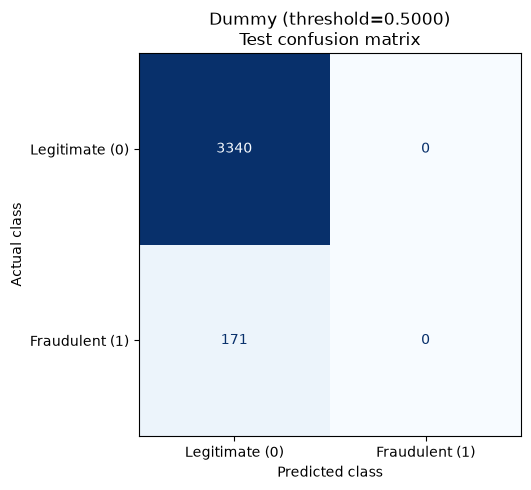

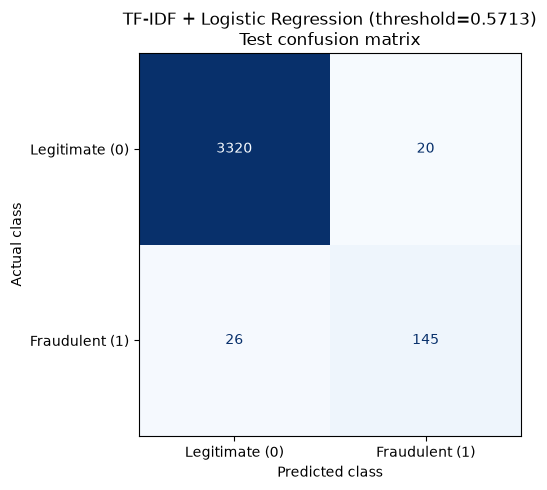

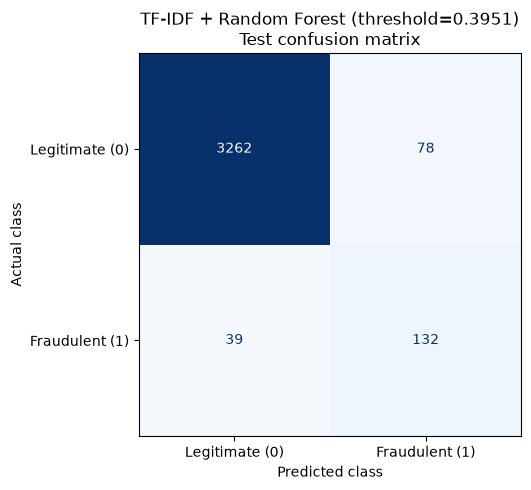

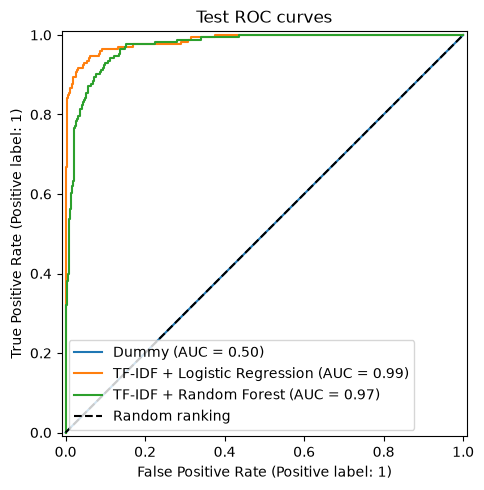

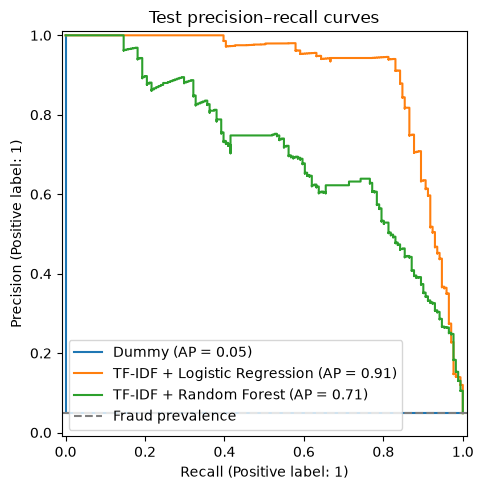

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

def plot_confusion_matrix(actual, predicted, model_name, save_path=None, show=True):
    # Rows are actual classes; columns are predicted classes.
    # With labels=[0, 1], the cells are [[TN, FP], [FN, TP]].
    matrix = confusion_matrix(actual, predicted, labels=[0, 1])
    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Legitimate (0)", "Fraudulent (1)"],
    )
    fig, ax = plt.subplots(figsize=(6, 5))
    display.plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False,
        im_kw={"vmin": 0},
    )
    ax.set_title(f"{model_name}\nTest confusion matrix")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    return matrix

def plot_test_results(predictions, save_dir=None):
    # Draw charts from saved predictions, without fitting or evaluating models.
    for number, item in enumerate(predictions, start=1):
        save_path = None
        if save_dir is not None:
            save_path = save_dir / f"tfidf_test_confusion_{number}.png"
        plot_confusion_matrix(
            item["actual"], item["predicted"],
            f'{item["name"]} (threshold={item["threshold"]:.4f})',
            save_path=save_path, show=False,
        )
    roc_fig, roc_ax = plt.subplots(figsize=(6, 5))
    pr_fig, pr_ax = plt.subplots(figsize=(6, 5))
    for item in predictions:
        RocCurveDisplay.from_predictions(
            item["actual"], item["probabilities"], name=item["name"], ax=roc_ax,
        )
        PrecisionRecallDisplay.from_predictions(
            item["actual"], item["probabilities"], name=item["name"], ax=pr_ax,
        )
    roc_ax.plot([0, 1], [0, 1], "k--", label="Random ranking")
    roc_ax.set_title("Test ROC curves")
    roc_ax.legend()
    prevalence = predictions[0]["actual"].mean()
    pr_ax.axhline(prevalence, color="gray", linestyle="--", label="Fraud prevalence")
    pr_ax.set_title("Test precision–recall curves")
    pr_ax.legend()
    roc_fig.tight_layout()
    pr_fig.tight_layout()
    if save_dir is not None:
        roc_fig.savefig(save_dir / "tfidf_test_roc.png", dpi=150, bbox_inches="tight")
        pr_fig.savefig(save_dir / "tfidf_test_precision_recall.png", dpi=150, bbox_inches="tight")
    plt.show()

plot_test_results(saved_predictions, save_dir=Path("data"))

### TF-IDF findings

Logistic Regression has higher test F1 (**0.8631 vs 0.6929**) and AP (**0.9050 vs 0.7111**) than Random Forest.

Logistic Regression detects **145 of 171** fraudulent postings, misses **26**, and raises **20** false alarms. Random Forest detects **132**, misses **39**, and raises **78** false alarms. Logistic Regression finds more fraud and gives far more reliable fraud alerts. Dummy achieves **95.13% accuracy** while detecting no fraud.

These findings apply to the tested configurations. Comparing TF-IDF with embeddings still requires the team's test results. We do not tune further using these test scores.

# 5. Possible future development

- **This project could be enhanced in various ways:**

1. When comparing TF-IDF and Embeddings, only the 5 text columns were used. This is a great starting point, but it would be interesting to see, if appending embeddings directly other variables from the dataset leads to a better result.

2. Using different concatenating techniques of the text columns instead of plain-space joining: adding short labels `Title: ... | Company: Missing | Description: ...` during concatenation could give the embedding model a clearer context.

# 6. Who did what and the use of AI

We worked as a team during the creation of the project and collaborated on it via our GitHub repository: https://github.com/noamorii/4IZ582-fraudulent-job-detection

1. **Nastya**
- Analyzed class balance, plotted real vs. fraudulent postings
- Handled missing values across text columns
- Built DummyClassifier
- Built and tuned TF-IDF → Logistic Regression and TF-IDF → Random Forest

2. **Julia**
- Analyzed missing values across columns
- Handled duplicates and conflicting labels, created the test holdout and shared CV splits
- Generated and saved text embeddings via the school endpoint
- Built and tuned Embeddings → Logistic Regression.

3. **Olesia**
- Investigated duplicates and metadata features (company logo, employment type, remote work) and plotted their relationship with fraud.
- Cleaned HTML tags and extra spaces, dropped empty postings
- Built cache for the Jupyter Notebook 
- Built and tuned Embeddings → Random Forest

Generative AI was used during the creation of this project in concordance with the policy of this course (as described on GitLab).

